# Nested Sampling with `dynesty`: Advanced Usage

This demo covers a few more advanced features of `dynesty`: continuing a finished run, running the sampler as a generator, dynamic sampling with a fixed computational budget, and some additional plotting functions. It assumes you are familiar with the basics covered in the Overview demo, and uses the same target distribution. See the [documentation](https://dynesty.readthedocs.io) for more details.

## Setup

In [1]:
# system functions that are always useful to have
import time, sys, os

# basic numeric setup
import numpy as np
from numpy import linalg

# inline plotting
%matplotlib inline

# plotting
import matplotlib
from matplotlib import pyplot as plt

# seed the random number generator
rstate = np.random.default_rng(5647)

# plotting defaults
from matplotlib import rcParams
rcParams.update({'font.size': 20})

In [2]:
import dynesty

In [3]:
ndim = 3  # number of dimensions
C = np.identity(ndim)  # set covariance to identity matrix
C[C==0] = 0.95  # set off-diagonal terms (strongly correlated)
Cinv = linalg.inv(C)  # precision matrix
lnorm = -0.5 * (np.log(2 * np.pi) * ndim + np.log(linalg.det(C)))  # ln(normalization)

# 3-D correlated multivariate normal log-likelihood
def loglikelihood(x):
    """Multivariate normal log-likelihood."""
    return -0.5 * np.dot(x, np.dot(Cinv, x)) + lnorm

In [4]:
# prior transform
def prior_transform(u):
    """Transforms our unit cube samples `u` to a flat prior between -10. and 10. in each variable."""
    return 10. * (2. * u - 1.)

# Continuing a Run

Let's first run the sampler with the default stopping criterion.

In [5]:
sampler = dynesty.NestedSampler(loglikelihood, prior_transform, ndim, nlive=1500,
                                rstate=rstate)
sampler.run_nested(print_progress=False)
res = sampler.results
res.summary()

Summary
nlive: 1500
niter: 12611
ncall: 64724
eff(%): 21.802
logz: -9.040 +/-  0.070


`dynesty` keeps track of the live points, so a finished run can be continued with a more stringent stopping criterion. The final set of live points that was added to the samples at the end of the first run is removed, the sampling continues until the new criterion is met, and the live points are added again.

In [6]:
sampler.run_nested(dlogz=0.01, print_progress=False)
res2 = sampler.results
res2.summary()

Summary
nlive: 1500
niter: 20046
ncall: 76193
eff(%): 28.278
logz: -9.043 +/-  0.070


The number of samples increased from about 12600 to about 20000, but the evidence and its uncertainty are practically unchanged. This is because the final set of live points added to the samples at the end of the first run already covered the rest of the posterior well, which is why the default stopping criterion is sufficient for evidence estimation.

# Running the Sampler as a Generator

Instead of calling `run_nested()`, the sampler can also be run as a **generator** using the `sample()` method, which yields the results of each iteration. This gives full control over the run: for example, you can monitor the run in your own way or implement your own stopping condition. Below we print the progress every 1000 iterations and stop once the estimated remaining contribution to the log-evidence (`delta_logz`) drops below 0.5 (we pass `dlogz=0` so that the built-in stopping criterion is never met). Once we are done, the final set of live points is added to the samples using `add_live_points()`.

In [7]:
gsampler = dynesty.NestedSampler(loglikelihood, prior_transform, ndim, nlive=1500,
                                 rstate=rstate)
for it, result in enumerate(gsampler.sample(dlogz=0.)):
    if (it + 1) % 1000 == 0:
        print('iteration {:5d}: logl* = {:8.3f}, logz = {:7.3f}, delta_logz = {:7.3f}'.format(
            it + 1, result.loglstar, result.logz, result.delta_logz))
    # our own stopping condition
    if result.delta_logz < 0.5:
        break

# add the final set of live points to the samples
for result in gsampler.add_live_points():
    pass
gsampler.results.summary()

iteration  1000: logl* = -576.102, logz = -582.769, delta_logz = 581.265


iteration  2000: logl* = -259.731, logz = -267.211, delta_logz = 265.215


iteration  3000: logl* = -130.914, logz = -137.528, delta_logz = 134.615


iteration  4000: logl* =  -71.319, logz = -78.053, delta_logz =  74.560


iteration  5000: logl* =  -43.699, logz = -50.415, delta_logz =  46.237


iteration  6000: logl* =  -27.871, logz = -34.750, delta_logz =  30.256


... (5 outputs left out)

iteration 12000: logl* =   -2.063, logz = -10.086, delta_logz =   1.933


iteration 13000: logl* =   -1.442, logz =  -9.566, delta_logz =   1.031


iteration 14000: logl* =   -1.034, logz =  -9.269, delta_logz =   0.531


Summary
nlive: 1500
niter: 14087
ncall: 67634
eff(%): 23.046
logz: -8.895 +/-  0.070


The resulting evidence is consistent with the true value ($\ln \mathcal{Z} = -3 \ln 20 \approx -8.99$) given its uncertainty.

# Dynamic Sampling with a Fixed Budget

By default, `DynamicNestedSampler` adds batches of live points until its stopping criterion is met (see the Dynamic Nested Sampling demo). Alternatively, the computational budget can be fixed: `maxiter` (or `maxcall`) limits the total number of iterations (or likelihood calls), and `use_stop=False` disables the stopping criterion, so batches are added until the budget is used up. This is useful, for example, to compare different weight functions at the same cost. Below we compare a posterior-oriented run (`pfrac=1`) and an evidence-oriented run (`pfrac=0`) with the same number of samples.

In [8]:
from dynesty.utils import get_neff_from_logwt

maxiter = 20000
dsampler = dynesty.DynamicNestedSampler(loglikelihood, prior_transform, ndim,
                                        nlive=500, rstate=rstate)
dres = {}
for pfrac in [1.0, 0.0]:
    dsampler.reset()
    dsampler.run_nested(maxiter=maxiter, use_stop=False, wt_kwargs={'pfrac': pfrac},
                        print_progress=False)
    dres[pfrac] = dsampler.results

print('pfrac   niter  logz               n_eff')
for pfrac, r in dres.items():
    print('{:5.1f} {:7d}  {:6.3f} +/- {:5.3f}  {:6.0f}'.format(
        pfrac, r.niter, r.logz[-1], r.logzerr[-1], get_neff_from_logwt(r.logwt)))

/home/skoposov/curwork/dynesty/py/dynesty/sampler.py:1122: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'


/home/skoposov/curwork/dynesty/py/dynesty/sampler.py:1122: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'


pfrac   niter  logz               n_eff
  1.0   20001  -8.908 +/- 0.114   15459
  0.0   20040  -9.086 +/- 0.061    4076


With the same number of samples, the posterior-oriented run has almost four times as many effective posterior samples, while the evidence-oriented run has an evidence error about half as large. Both evidences agree with the true value ($\approx -8.99$) within two standard deviations. The warnings are expected: the last batch of each run is stopped by the `maxiter` limit.

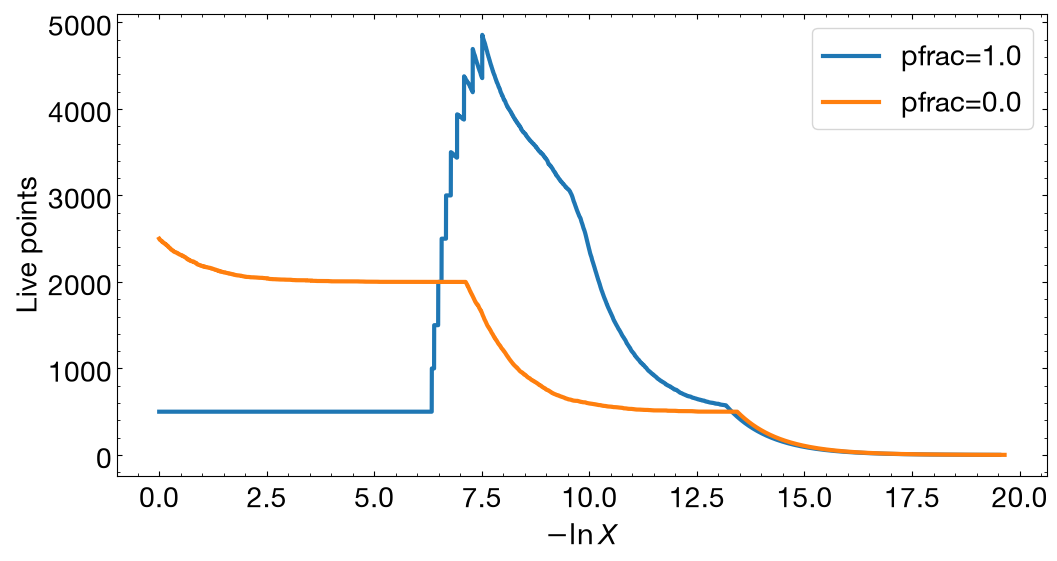

In [9]:
plt.figure(figsize=(12, 6))
for pfrac, r in dres.items():
    plt.plot(-r.logvol, r.samples_n, lw=3, label='pfrac={}'.format(pfrac))
plt.xlabel(r'$-\ln X$')
plt.ylabel('Live points')
plt.legend();

The posterior-oriented run places the additional live points around the bulk of the posterior mass, while the evidence-oriented run places them from the start of the run until the bulk of the posterior mass. The small excess of live points at the very start of the evidence-oriented run comes from its last batch, which was cut short by `maxiter`.

# More Plotting Functions

In addition to the plots shown in the Overview demo, `dynesty` can show the positions of the samples colored by their importance weights in a corner-plot format using `cornerpoints`.

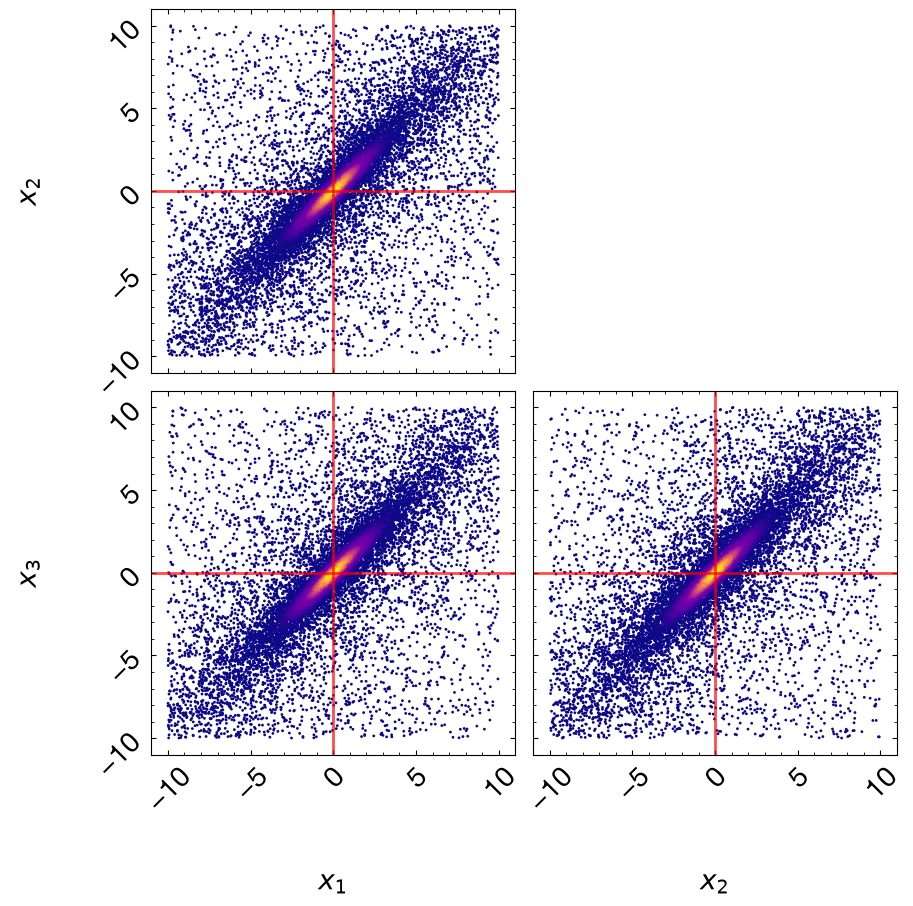

In [10]:
from dynesty import plotting as dyplot

fig, axes = dyplot.cornerpoints(res, cmap='plasma', truths=[0., 0., 0.], kde=False,
                                fig=plt.subplots(2, 2, figsize=(10, 10)))

Similarly, `cornerbound` shows the bounding distribution used to propose new points at a given iteration (here drawn as a set of points sampled from it), together with the live points.

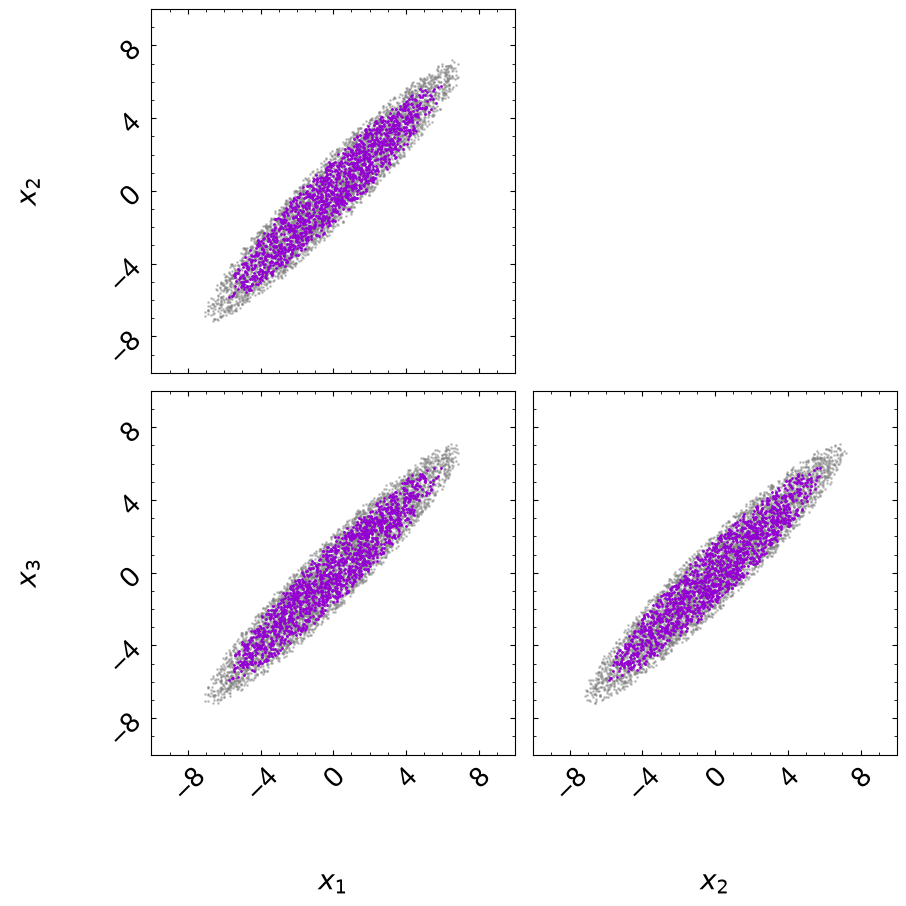

In [11]:
fig, axes = dyplot.cornerbound(res, it=7000, prior_transform=prior_transform, show_live=True,
                               span=[(-10, 10), (-10, 10), (-10, 10)],
                               fig=plt.subplots(2, 2, figsize=(10, 10)))